## EDA AND PREPROCESSING

--------------------------

## Planned model labels

### Civil Comments model
This model will predict:
- Broad toxicity
- Obscene/profane language
- Insults
- Threats
- Identity attacks
- Sexually explicit content

### Davidson model
The `class` column means:
- `0` = hate speech
- `1` = offensive language
- `2` = neither

For the broad abuse prediction, classes `0` and `1` will count as abusive, and class `2` as non-abusive. Davidson does not have separate labels for threats, insults, or profanity.

### Ensemble
The two models will contribute to a shared broad abuse prediction. The Civil Comments model will provide the more specific category predictions.

------------------------------

#### IMPORTING LIBRARIES

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# EDA-CIVIL_DATASET


In [28]:
civil_df = pd.read_csv("civil_comments_sample.csv")
davidson_df = pd.read_csv("train.csv")

In [29]:
civil_df.shape

(50000, 8)

In [30]:
civil_df.describe()

,toxicity,severe_toxicity,obscene,threat,insult,identity_attack,sexual_explicit
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,0.103082,0.004604,0.013997,0.009351,0.081054,0.022486,0.006496
std,0.196056,0.022900,0.065570,0.048949,0.174806,0.078174,0.044575
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.166667,0.000000,0.000000,0.000000,0.100000,0.000000,0.000000
max,1.000000,0.500000,1.000000,1.000000,1.000000,1.000000,0.909028


In [31]:
civil_df.head()

,text,toxicity,severe_toxicity,obscene,threat,insult,identity_attack,sexual_explicit
0,Socialists? What the hell does that have to do...,0.300000,0.000000,0.300000,0.0,0.200000,0.0,0.0
1,And I always thought that Eric Trump was the d...,0.808824,0.029412,0.088235,0.0,0.794118,0.0,0.0
2,I’m disappointed there’s no report from CB on ...,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.0
3,Nothing like subsidizing a country that is thr...,0.166667,0.000000,0.000000,0.0,0.166667,0.0,0.0
4,The only way to save the rhino is to legalize ...,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.0


In [32]:
civil_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   text             50000 non-null  str    
 1   toxicity         50000 non-null  float64
 2   severe_toxicity  50000 non-null  float64
 3   obscene          50000 non-null  float64
 4   threat           50000 non-null  float64
 5   insult           50000 non-null  float64
 6   identity_attack  50000 non-null  float64
 7   sexual_explicit  50000 non-null  float64
dtypes: float64(7), str(1)
memory usage: 17.2 MB


#### preprocessing

In [33]:
civil_df.isnull().sum()

text               0
toxicity           0
severe_toxicity    0
obscene            0
threat             0
insult             0
identity_attack    0
sexual_explicit    0
dtype: int64

In [34]:
civil_df.duplicated().sum()

np.int64(66)

In [35]:
civil_df["text"].duplicated().sum()

np.int64(75)

In [36]:
label_columns = [
    "toxicity", "severe_toxicity", "obscene", "threat",
    "insult", "identity_attack", "sexual_explicit"
]

repeated_text = civil_df[civil_df["text"].duplicated(keep=False)]

display(
    repeated_text[["text"] + label_columns]
    .sort_values("text")
    .head(50000)
)

,text,toxicity,severe_toxicity,obscene,threat,insult,identity_attack,sexual_explicit
6276,"""If you build it, they will come"".",0.000000,0.0,0.0,0.0,0.000000,0.0,0.0
9955,"""If you build it, they will come"".",0.000000,0.0,0.0,0.0,0.000000,0.0,0.0
16145,.,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0
33569,.,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0
25662,Agreed.,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0
...,...,...,...,...,...,...,...,...
20271,tgam test,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0
22947,troll,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0
42510,troll,0.300000,0.0,0.0,0.0,0.300000,0.0,0.0
24185,‪Please sign petition for US President Trump t...,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0


In [37]:
label_columns = [
    "toxicity", "severe_toxicity", "obscene", "threat",
    "insult", "identity_attack", "sexual_explicit"
]

# Make a working copy and remove rows identical across every column
civil_clean = civil_df.drop_duplicates().copy()

print("Rows before:", len(civil_df))
print("Rows after exact-duplicate removal:", len(civil_clean))

# Check whether any repeated text has different labels
label_conflicts = (
    civil_clean.groupby("text")[label_columns]
    .nunique()
    .gt(1)
    .any(axis=1)
)

print("Repeated texts with different label scores:", label_conflicts.sum())

Rows before: 50000
Rows after exact-duplicate removal: 49934
Repeated texts with different label scores: 9


In [38]:
civil_clean = civil_clean.drop_duplicates(subset="text", keep="first").copy()

print("Rows after text deduplication:", len(civil_clean))
print("Repeated texts remaining:", civil_clean["text"].duplicated().sum())

Rows after text deduplication: 49925
Repeated texts remaining: 0


- We found out using `.duplicated().sum()` that some rows were duplicated. First, we checked how many rows there were, and we then dealt with it. 
- There were 66 rows that were duplicated, 9 repeated texts so we removed those duplicated rows and saved it in another copy. 
- Then we saw that Some duplicated rows after deduplicating were still left that had repeated texts with different label scores, so we removed them also. 

In [39]:
label_columns = [
    "toxicity", "severe_toxicity", "obscene", "threat",
    "insult", "identity_attack", "sexual_explicit"
]

civil_exact_clean = civil_df.drop_duplicates().copy()

civil_clean = (
    civil_exact_clean
    .groupby("text", as_index=False)[label_columns]
    .mean()
)

print("Rows after removing exact duplicate rows:", len(civil_exact_clean))
print("Rows after grouping repeated text:", len(civil_clean))
print("Repeated texts remaining:", civil_clean["text"].duplicated().sum())

Rows after removing exact duplicate rows: 49934
Rows after grouping repeated text: 49925
Repeated texts remaining: 0


-----------------------------

# EDA-DAVISON DATASET

In [40]:
davidson_df.head()


,count,hate_speech_count,offensive_language_count,neither_count,class,tweet
0,3,0,0,3,2,!!! RT @mayasolovely: As a woman you shouldn't...
1,3,0,3,0,1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...
2,3,0,3,0,1,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...
3,3,0,2,1,1,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...
4,6,0,6,0,1,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...


In [41]:
davidson_df.shape


(24783, 6)

In [42]:
davidson_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 24783 entries, 0 to 24782
Data columns (total 6 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   count                     24783 non-null  int64
 1   hate_speech_count         24783 non-null  int64
 2   offensive_language_count  24783 non-null  int64
 3   neither_count             24783 non-null  int64
 4   class                     24783 non-null  int64
 5   tweet                     24783 non-null  str  
dtypes: int64(5), str(1)
memory usage: 3.2 MB


#### preprocessing

In [43]:
davidson_df.isnull().sum()


count                       0
hate_speech_count           0
offensive_language_count    0
neither_count               0
class                       0
tweet                       0
dtype: int64

In [44]:
davidson_df.duplicated().sum()


np.int64(0)

In [45]:
davidson_df["class"].value_counts()

class
1    19190
2     4163
0     1430
Name: count, dtype: int64

In [46]:
label_columns = [
    "toxicity", "severe_toxicity", "obscene", "threat",
    "insult", "identity_attack", "sexual_explicit"
]

print("CIVIL COMMENTS")
print("Rows:", len(civil_clean))
print("Missing values:")
print(civil_clean[["text"] + label_columns].isnull().sum())
print("Label score summaries:")
print(civil_clean[label_columns].describe().round(3))

print("\nDAVIDSON")
print("Rows:", len(davidson_df))
print("Missing values:")
print(davidson_df[["tweet", "class"]].isnull().sum())
print("Class counts (0=hate speech, 1=offensive, 2=neither):")
print(davidson_df["class"].value_counts().sort_index())

CIVIL COMMENTS
Rows: 49925
Missing values:
text               0
toxicity           0
severe_toxicity    0
obscene            0
threat             0
insult             0
identity_attack    0
sexual_explicit    0
dtype: int64
Label score summaries:
        toxicity  severe_toxicity    obscene     threat     insult  \
count  49925.000        49925.000  49925.000  49925.000  49925.000   
mean       0.103            0.005      0.014      0.009      0.081   
std        0.196            0.023      0.066      0.049      0.175   
min        0.000            0.000      0.000      0.000      0.000   
25%        0.000            0.000      0.000      0.000      0.000   
50%        0.000            0.000      0.000      0.000      0.000   
75%        0.167            0.000      0.000      0.000      0.100   
max        1.000            0.500      1.000      1.000      1.000   

       identity_attack  sexual_explicit  
count        49925.000        49925.000  
mean             0.023            0.00

## TRAIN TEST SPLIT

In [48]:
civil_data = civil_clean.copy()
davidson_data = davidson_df.copy()

civil_data["abusive"] = (civil_data["toxicity"] >= 0.5).astype(int)
civil_data["obscene_profane"] = (civil_data["obscene"] >= 0.5).astype(int)
civil_data["insult_label"] = (civil_data["insult"] >= 0.5).astype(int)
civil_data["threat_label"] = (civil_data["threat"] >= 0.5).astype(int)
civil_data["identity_attack_label"] = (civil_data["identity_attack"] >= 0.5).astype(int)
civil_data["sexual_explicit_label"] = (civil_data["sexual_explicit"] >= 0.5).astype(int)

# Davidson classes 0 and 1 mean abusive; class 2 means non-abusive
davidson_data["abusive"] = (davidson_data["class"].isin([0, 1]).astype(int))

# Split Civil Comments into training and test sets
civil_train, civil_test = train_test_split(
    civil_data,
    test_size=0.30,
    random_state=42
)

# Split Davidson, preserving the abusive/non-abusive proportions
davidson_train, davidson_test = train_test_split(
    davidson_data,
    test_size=0.30,
    random_state=42,
    stratify=davidson_data["abusive"]
)

print("Civil training rows:", len(civil_train))
print("Civil test rows:", len(civil_test))
print("\nDavidson training rows:", len(davidson_train))
print("Davidson test rows:", len(davidson_test))

Civil training rows: 34947
Civil test rows: 14978

Davidson training rows: 17348
Davidson test rows: 7435


keep comments seperate

In [49]:
civil_text_train = civil_train["text"].astype(str)
civil_text_test = civil_test["text"].astype(str)

civil_labels = [
    "abusive",
    "obscene_profane",
    "insult_label",
    "threat_label",
    "identity_attack_label",
    "sexual_explicit_label"
]

civil_targets_train = civil_train[civil_labels]
civil_targets_test = civil_test[civil_labels]


davidson_text_train = davidson_train["tweet"].astype(str)
davidson_text_test = davidson_test["tweet"].astype(str)

davidson_targets_train = davidson_train["abusive"]
davidson_targets_test = davidson_test["abusive"]


print("Civil training text:", civil_text_train.shape)
print("Civil training labels:", civil_targets_train.shape)
print("Davidson training text:", davidson_text_train.shape)
print("Davidson training labels:", davidson_targets_train.shape)

Civil training text: (34947,)
Civil training labels: (34947, 6)
Davidson training text: (17348,)
Davidson training labels: (17348,)


## traing the davison model

In [55]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

davidson_model = Pipeline([
    ("word_counts", CountVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=2
    )),
    ("classifier", LogisticRegression(max_iter=1000))
])

davidson_model.fit(davidson_text_train, davidson_targets_train)

print("Davidson model training complete.")

Davidson model training complete.


# evaluation

Accuracy: 0.953

Classification report:
              precision    recall  f1-score   support

 Non-abusive       0.85      0.87      0.86      1249
     Abusive       0.97      0.97      0.97      6186

    accuracy                           0.95      7435
   macro avg       0.91      0.92      0.92      7435
weighted avg       0.95      0.95      0.95      7435



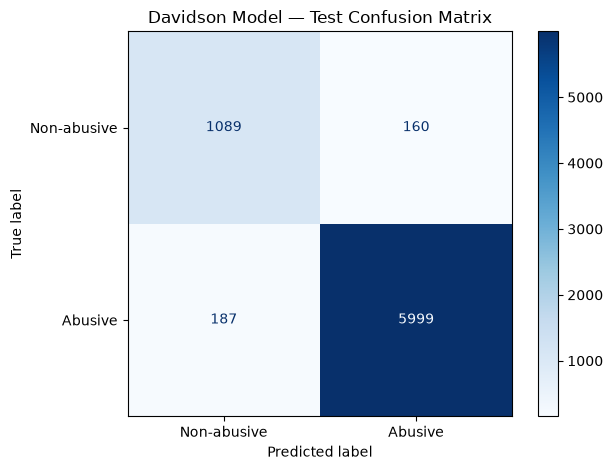

In [56]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

davidson_predictions = davidson_model.predict(davidson_text_test)

print("Accuracy:", round(
    accuracy_score(davidson_targets_test, davidson_predictions), 3
))

print("\nClassification report:")
print(classification_report(
    davidson_targets_test,
    davidson_predictions,
    labels=[0, 1],
    target_names=["Non-abusive", "Abusive"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    davidson_targets_test,
    davidson_predictions,
    labels=[0, 1],
    display_labels=["Non-abusive", "Abusive"],
    cmap="Blues"
)

plt.title("Davidson Model — Test Confusion Matrix")
plt.tight_layout()
plt.show()

## training the civil comments model

In [57]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multioutput import MultiOutputClassifier
from sklearn.pipeline import Pipeline

civil_model = Pipeline([
    ("word_counts", CountVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=2
    )),
    ("classifiers", MultiOutputClassifier(
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        )
    ))
])

civil_model.fit(civil_text_train, civil_targets_train)

print("Civil Comments model training complete.")

Civil Comments model training complete.


# evaluation


abusive
              precision    recall  f1-score   support

          No       0.96      0.94      0.95     13776
         Yes       0.46      0.55      0.50      1202

    accuracy                           0.91     14978
   macro avg       0.71      0.75      0.73     14978
weighted avg       0.92      0.91      0.92     14978


obscene_profane
              precision    recall  f1-score   support

          No       1.00      1.00      1.00     14893
         Yes       0.29      0.24      0.26        85

    accuracy                           0.99     14978
   macro avg       0.64      0.62      0.63     14978
weighted avg       0.99      0.99      0.99     14978


insult_label
              precision    recall  f1-score   support

          No       0.97      0.96      0.97     14099
         Yes       0.49      0.58      0.53       879

    accuracy                           0.94     14978
   macro avg       0.73      0.77      0.75     14978
weighted avg       0.95      0.94 

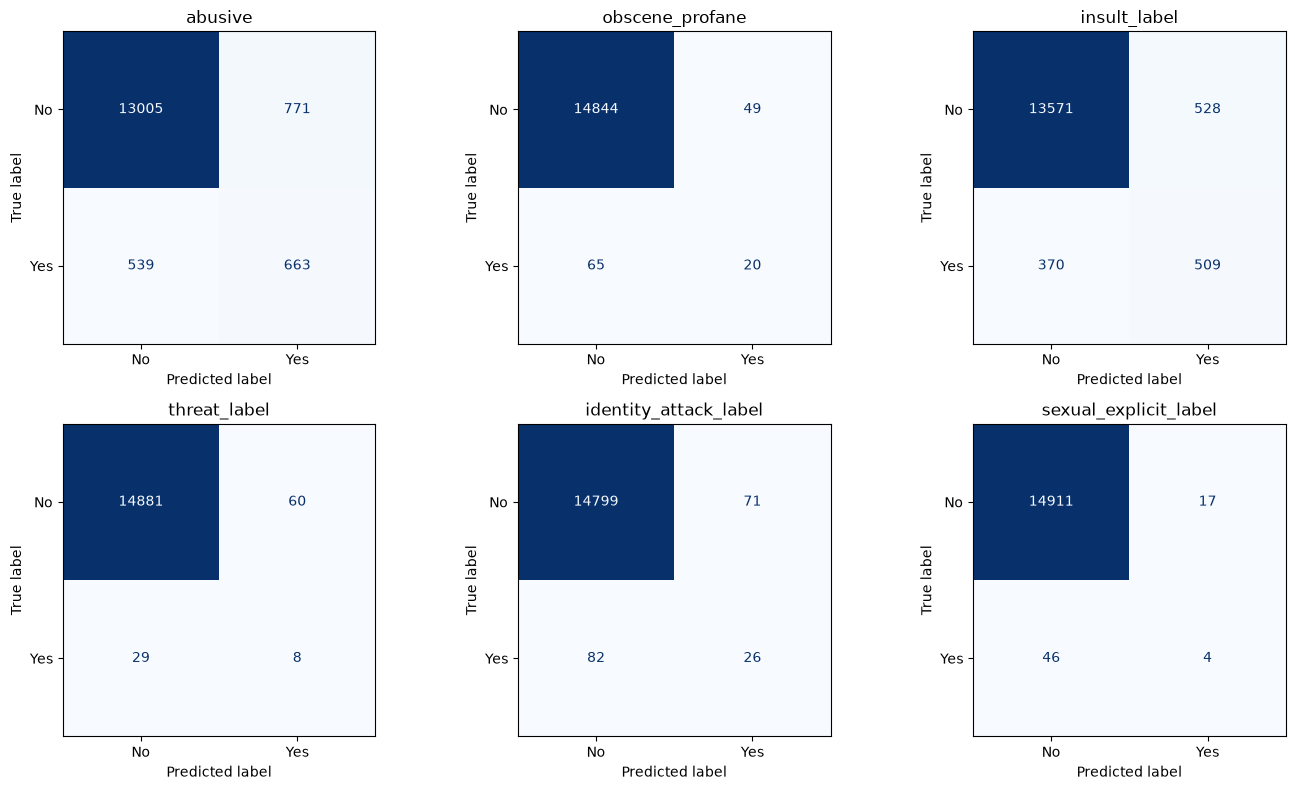

In [58]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

civil_predictions = civil_model.predict(civil_text_test)

for i, label in enumerate(civil_labels):
    print(f"\n{label}")
    print(classification_report(
        civil_targets_test.iloc[:, i],
        civil_predictions[:, i],
        labels=[0, 1],
        target_names=["No", "Yes"],
        zero_division=0
    ))

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, label in enumerate(civil_labels):
    ConfusionMatrixDisplay.from_predictions(
        civil_targets_test.iloc[:, i],
        civil_predictions[:, i],
        labels=[0, 1],
        display_labels=["No", "Yes"],
        cmap="Blues",
        ax=axes[i],
        colorbar=False
    )
    axes[i].set_title(label)

plt.tight_layout()
plt.show()

-----------------------

# Combined Model Evaluation

Combined predictions on Civil Comments test data
              precision    recall  f1-score   support

 Non-abusive       0.96      0.68      0.80     13776
     Abusive       0.16      0.71      0.27      1202

    accuracy                           0.68     14978
   macro avg       0.56      0.70      0.53     14978
weighted avg       0.90      0.68      0.76     14978

Combined predictions on Davidson test data
              precision    recall  f1-score   support

 Non-abusive       0.87      0.74      0.80      1249
     Abusive       0.95      0.98      0.96      6186

    accuracy                           0.94      7435
   macro avg       0.91      0.86      0.88      7435
weighted avg       0.94      0.94      0.94      7435



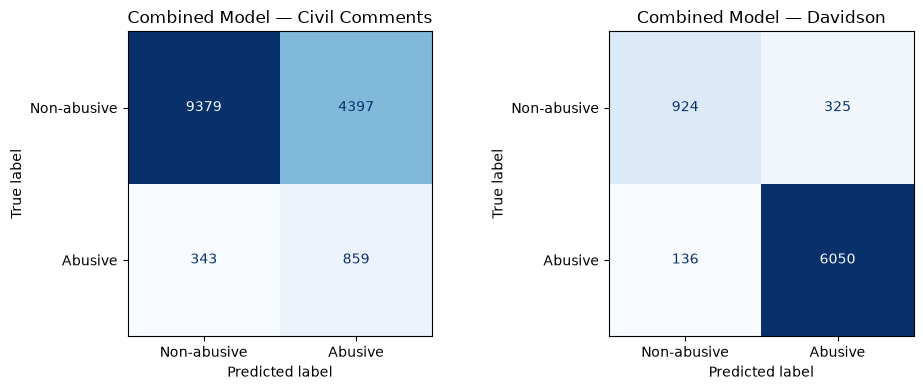

In [60]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Predictions on the Civil Comments test set
civil_abusive_prediction = civil_model.predict(civil_text_test)[:, 0]
civil_davidson_prediction = davidson_model.predict(civil_text_test)

civil_combined_prediction = (
    (civil_abusive_prediction == 1) |
    (civil_davidson_prediction == 1)
).astype(int)

# Predictions on the Davidson test set
# Predict using both models on the Davidson test text
davidson_civil_prediction = civil_model.predict(davidson_text_test)[:, 0]
davidson_model_prediction = davidson_model.predict(davidson_text_test)

# Mark a comment abusive if either model predicts abusive
davidson_combined_prediction = (
    (davidson_model_prediction == 1) |
    (davidson_civil_prediction == 1)
).astype(int)

print("Combined predictions on Civil Comments test data")
print(classification_report(
    civil_targets_test["abusive"],
    civil_combined_prediction,
    target_names=["Non-abusive", "Abusive"],
    zero_division=0
))

print("Combined predictions on Davidson test data")
print(classification_report(
    davidson_targets_test,
    davidson_combined_prediction,
    target_names=["Non-abusive", "Abusive"],
    zero_division=0
))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay.from_predictions(
    civil_targets_test["abusive"],
    civil_combined_prediction,
    display_labels=["Non-abusive", "Abusive"],
    cmap="Blues",
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("Combined Model — Civil Comments")

ConfusionMatrixDisplay.from_predictions(
    davidson_targets_test,
    davidson_combined_prediction,
    display_labels=["Non-abusive", "Abusive"],
    cmap="Blues",
    ax=axes[1],
    colorbar=False
)
axes[1].set_title("Combined Model — Davidson")

plt.tight_layout()
plt.show()